## Stereo and Epipolar Geometry

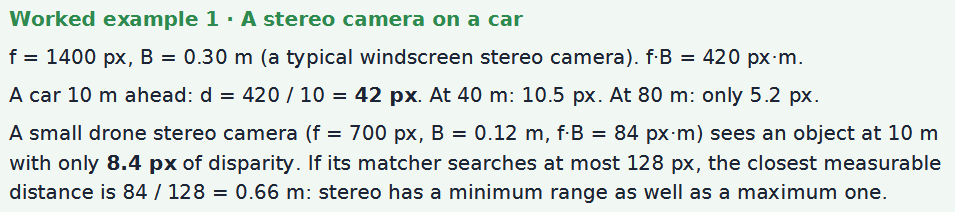

car camera:   f·B = 420 px·m
  object at 10 m -> disparity  42.0 px
  object at 40 m -> disparity  10.5 px
  object at 80 m -> disparity   5.2 px

drone camera: f·B = 84 px·m
  object at 10 m -> disparity 8.4 px
  closest measurable distance (d = 128 px): 0.66 m


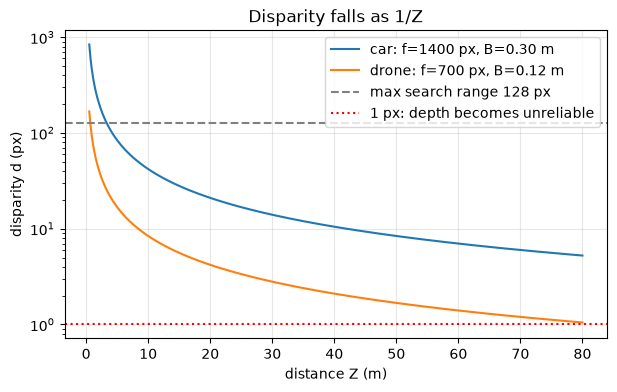

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def disparity_px(f_px, baseline_m, Z_m):
    """Disparity in pixels for an object at depth Z:  d = f·B / Z"""
    return f_px * baseline_m / Z_m

def depth_m(f_px, baseline_m, d_px):
    """Depth from disparity:  Z = f·B / d"""
    return f_px * baseline_m / d_px

# --- car windscreen stereo camera ---
f_car, B_car = 1400, 0.30
print(f"car camera:   f·B = {f_car * B_car:.0f} px·m")
for Z in [10, 40, 80]:
    print(f"  object at {Z:2d} m -> disparity {disparity_px(f_car, B_car, Z):5.1f} px")

# --- small drone stereo camera ---
f_dr, B_dr = 700, 0.12
max_disp = 128                       
print(f"\ndrone camera: f·B = {f_dr * B_dr:.0f} px·m")
print(f"  object at 10 m -> disparity {disparity_px(f_dr, B_dr, 10):.1f} px")
print(f"  closest measurable distance (d = {max_disp} px): {depth_m(f_dr, B_dr, max_disp):.2f} m")

# --- plot: disparity against distance for both cameras ---
Z = np.linspace(0.5, 80, 400)
plt.figure(figsize=(7, 4))
plt.plot(Z, disparity_px(f_car, B_car, Z), label="car: f=1400 px, B=0.30 m")
plt.plot(Z, disparity_px(f_dr, B_dr, Z), label="drone: f=700 px, B=0.12 m")
plt.axhline(max_disp, ls="--", c="gray", label="max search range 128 px")
plt.axhline(1, ls=":", c="red", label="1 px: depth becomes unreliable")
plt.yscale("log")
plt.xlabel("distance Z (m)"); plt.ylabel("disparity d (px)")
plt.title("Disparity falls as 1/Z")
plt.legend(); plt.grid(alpha=0.3); plt.show()